# Milestone 3 EDA: the four quarters we have (2025Q3–2026Q2)

Exploration only; all logic lives in `src/`. Each chart is saved to
`docs/figures/` and followed by a short reading of what it shows.
Data: `data/processed/securities.duckdb` (`fund_quarter`, `positions`,
`stock_quarter`) plus the seed list's `style_guess`, which is a weak label.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
con = duckdb.connect(str(ROOT / "data/processed/securities.duckdb"), read_only=True)

seed = (pl.read_csv(ROOT / "data/reference/seed_funds.csv")
        .select("fund_name", "style_guess").unique()
        .with_columns(pl.col("fund_name").str.to_lowercase().str.replace_all(r"[^a-z0-9]+", "_")
                      .str.strip_chars("_").alias("fund_id")))

# Validated reference palette (light), slots in fixed order; checked with the
# dataviz skill's validate_palette.js: all gates pass on adjacent pairs.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
OTHER = "#b8b6b0"          # neutral bucket, deliberately not a series hue
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
SURFACE = "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list(
    "blue_gray_red", ["#104281", "#3987e5", "#f0efec", "#e66767", "#a52a2a"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


def save(fig, name):
    fig.savefig(FIG / name, dpi=160, bbox_inches="tight")
    print(f"saved docs/figures/{name}")

## 1. Positions and turnover by style

Two measures on different scales, so two panels sharing the style axis
(never a dual axis). Each dot is one fund (2026Q2; turnover is the mean over
the three quarters that have one); the bar marks the style's median.

saved docs/figures/01_positions_turnover_by_style.png


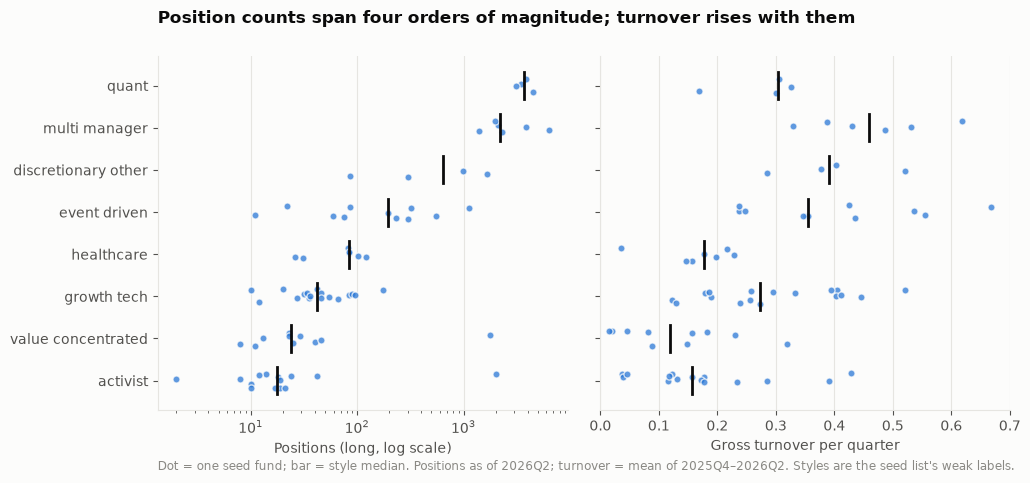

shape: (8, 5)
┌─────────────────────┬───────┬──────────────────┬───────────────────────┬─────────────────┐
│ style_guess         ┆ funds ┆ median_positions ┆ median_gross_turnover ┆ median_turnover │
│ ---                 ┆ ---   ┆ ---              ┆ ---                   ┆ ---             │
│ str                 ┆ u32   ┆ f64              ┆ f64                   ┆ f64             │
╞═════════════════════╪═══════╪══════════════════╪═══════════════════════╪═════════════════╡
│ activist            ┆ 15    ┆ 17.5             ┆ 0.157                 ┆ 0.098           │
│ value_concentrated  ┆ 11    ┆ 24.0             ┆ 0.119                 ┆ 0.066           │
│ growth_tech         ┆ 18    ┆ 42.0             ┆ 0.272                 ┆ 0.225           │
│ healthcare          ┆ 7     ┆ 84.0             ┆ 0.177                 ┆ 0.128           │
│ event_driven        ┆ 12    ┆ 197.0            ┆ 0.354                 ┆ 0.312           │
│ discretionary_other ┆ 4     ┆ 648.5            ┆ 0.39 

In [2]:
fq = con.execute("""
    SELECT fund_id, quarter, n_positions, turnover, gross_turnover FROM fund_quarter WHERE n_positions > 0
""").pl().join(seed.select("fund_id", "style_guess"), on="fund_id", how="left")
per_fund = fq.group_by("fund_id", "style_guess").agg(
    pl.col("n_positions").filter(pl.col("quarter") == "2026Q2").first().alias("n_positions"),  # as the caption says
    pl.col("turnover").mean().alias("turnover"),
    pl.col("gross_turnover").mean().alias("gross_turnover"),
)
order = (per_fund.group_by("style_guess").agg(pl.col("n_positions").median().alias("m"))
         .sort("m")["style_guess"].to_list())
rng = np.random.default_rng(0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, gridspec_kw={"wspace": 0.08})
for ax, col, label, log in [(axes[0], "n_positions", "Positions (long, log scale)", True),
                            (axes[1], "gross_turnover", "Gross turnover per quarter", False)]:
    for i, style in enumerate(order):
        v = per_fund.filter(pl.col("style_guess") == style)[col].drop_nulls().to_numpy()
        ax.scatter(v, i + rng.uniform(-0.18, 0.18, len(v)), s=26, color=SERIES[0], alpha=0.75,
                   edgecolor=SURFACE, linewidth=1, zorder=3)
        if len(v):
            ax.plot([np.median(v)] * 2, [i - 0.32, i + 0.32], color=INK, linewidth=2, zorder=4)
    ax.set_xscale("log" if log else "linear")
    ax.set_xlabel(label)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(order)), [s.replace("_", " ") for s in order])
axes[1].set_xlim(0, None)
fig.suptitle("Position counts span four orders of magnitude; turnover rises with them",
             x=0.125, ha="left", fontsize=12, fontweight="bold")
fig.text(0.125, -0.02, "Dot = one seed fund; bar = style median. Positions as of 2026Q2; turnover = mean of "
         "2025Q4–2026Q2. Styles are the seed list's weak labels.", color=MUTED, fontsize=8.5)
save(fig, "01_positions_turnover_by_style.png")
plt.show()

print(per_fund.group_by("style_guess").agg(
    pl.len().alias("funds"), pl.col("n_positions").median().alias("median_positions"),
    pl.col("gross_turnover").median().round(3).alias("median_gross_turnover"),
    pl.col("turnover").median().round(3).alias("median_turnover"),
).sort("median_positions"))

**Reading.** Position counts separate the styles cleanly: the median activist
holds about 18 names and the median concentrated value fund 24, growth/tech
funds 42, healthcare 84, event-driven about 200, while multi-managers (≈2,200)
and quants (≈3,700) hold thousands. Gross turnover broadly rises with breadth —
value-concentrated funds trade about 12% of the book a quarter and activists
16%, multi-managers 46% — but quants (30%) turn over less than multi-managers
or event-driven funds (35%). Within-style spread is wide (event-driven runs
from 11 to about 1,100 positions; activist gross turnover from 4% to 44%), so these two
features alone won't recover the styles.

## 2. The most crowded stocks, and how crowding changed

Crowding = number of seed funds holding the stock long. Dumbbell from 2025Q3
(gray) to 2026Q2 (blue); top 20 by 2026Q2 crowding. Share classes are kept
separate (GOOG vs GOOGL), as in the `positions` table.

saved docs/figures/02_most_crowded.png


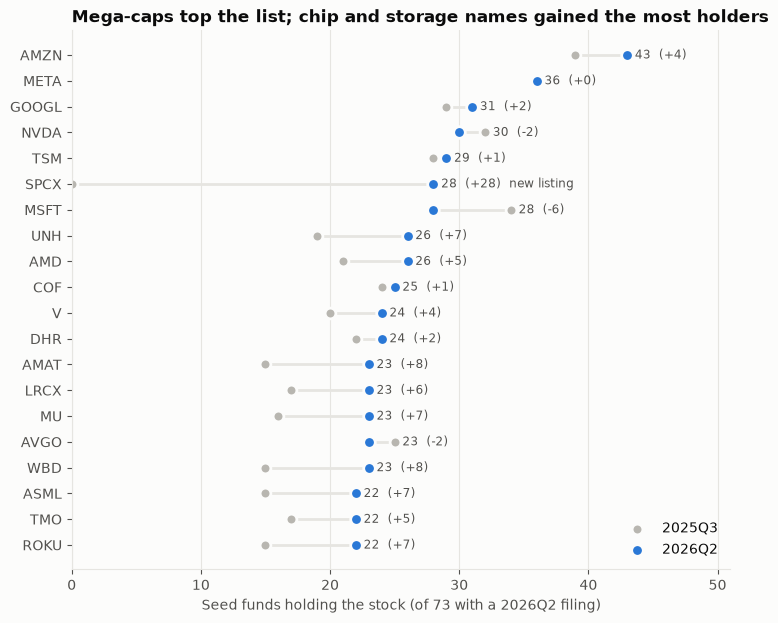

shape: (20, 4)
┌────────┬─────────┬─────────┬────────┐
│ symbol ┆ n_first ┆ n_funds ┆ change │
│ ---    ┆ ---     ┆ ---     ┆ ---    │
│ str    ┆ i64     ┆ i64     ┆ i64    │
╞════════╪═════════╪═════════╪════════╡
│ AMZN   ┆ 39      ┆ 43      ┆ 4      │
│ META   ┆ 36      ┆ 36      ┆ 0      │
│ GOOGL  ┆ 29      ┆ 31      ┆ 2      │
│ NVDA   ┆ 32      ┆ 30      ┆ -2     │
│ TSM    ┆ 28      ┆ 29      ┆ 1      │
│ …      ┆ …       ┆ …       ┆ …      │
│ AVGO   ┆ 25      ┆ 23      ┆ -2     │
│ WBD    ┆ 15      ┆ 23      ┆ 8      │
│ ASML   ┆ 15      ┆ 22      ┆ 7      │
│ TMO    ┆ 17      ┆ 22      ┆ 5      │
│ ROKU   ┆ 15      ┆ 22      ┆ 7      │
└────────┴─────────┴─────────┴────────┘


In [3]:
crowd = con.execute("""
    SELECT security_key AS symbol, quarter, count(DISTINCT fund_id) AS n_funds
    FROM positions WHERE NOT is_option AND security_class IN ('common', 'adr')
    GROUP BY ALL
""").pl()
last, first = crowd.filter(pl.col("quarter") == "2026Q2"), crowd.filter(pl.col("quarter") == "2025Q3")
top = (last.sort("n_funds", descending=True).head(20)
       .join(first.select("symbol", pl.col("n_funds").alias("n_first")), on="symbol", how="left")
       .with_columns(pl.col("n_first").fill_null(0), (pl.col("n_funds") - pl.col("n_first").fill_null(0)).alias("change"))
       .sort("n_funds"))
n_funds_total = con.execute("SELECT count(DISTINCT fund_id) FROM fund_quarter WHERE quarter = '2026Q2' AND n_positions > 0").fetchone()[0]

fig, ax = plt.subplots(figsize=(8.5, 7))
y = np.arange(len(top))
ax.hlines(y, top["n_first"], top["n_funds"], color=GRID, linewidth=2, zorder=1)
ax.scatter(top["n_first"], y, s=60, color=OTHER, edgecolor=SURFACE, linewidth=2, zorder=2, label="2025Q3")
ax.scatter(top["n_funds"], y, s=70, color=SERIES[0], edgecolor=SURFACE, linewidth=2, zorder=3, label="2026Q2")
for yi, (n, ch, n0) in enumerate(zip(top["n_funds"], top["change"], top["n_first"])):
    note = "  new listing" if n0 == 0 else ""   # e.g. a 2026 IPO: zero holders is not "uncrowded"
    ax.text(max(n, n0) + 0.6, yi, f"{n}  ({ch:+d}){note}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, top["symbol"].to_list())
ax.set_xlabel(f"Seed funds holding the stock (of {n_funds_total} with a 2026Q2 filing)")
ax.set_xlim(0, top["n_funds"].max() + 8)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
ax.set_title("Mega-caps top the list; chip and storage names gained the most holders")
save(fig, "02_most_crowded.png")
plt.show()
print(top.sort("n_funds", descending=True).select("symbol", "n_first", "n_funds", "change"))

**Reading.** Amazon is the most widely held stock (43 of the 73 funds that
filed for 2026Q2), followed by Meta (36), Alphabet, Nvidia and TSMC; SpaceX
(SPCX) went from not existing to 28 holders in its first quarter as a listed
stock. Semiconductor and storage names gained the most holders over the year
(Applied Materials and Seagate +8, Micron +7, Lam +6), while Microsoft lost 6
and Nvidia and Broadcom 2 each. Sixteen of these 20 gained holders, but that
is partly selection — ranking by end-of-period crowding favours names that
rose — and the ~10 quants and multi-managers hold nearly every large stock, so
crowding among the concentrated funds is the sharper measure for Milestone 5.
Apple is not on the list: only 17–22 seed funds held it in any quarter.

## 3. Factor tilts by fund, grouped by style

Rows = funds (2026Q2), columns = value-weighted average z-scores of the six
characteristics (stock z-scores are across stocks held by seed funds, so 0 =
the average hedge-fund holding). Diverging blue–red with a gray midpoint,
clipped at ±2σ.

saved docs/figures/03_factor_tilts_heatmap.png


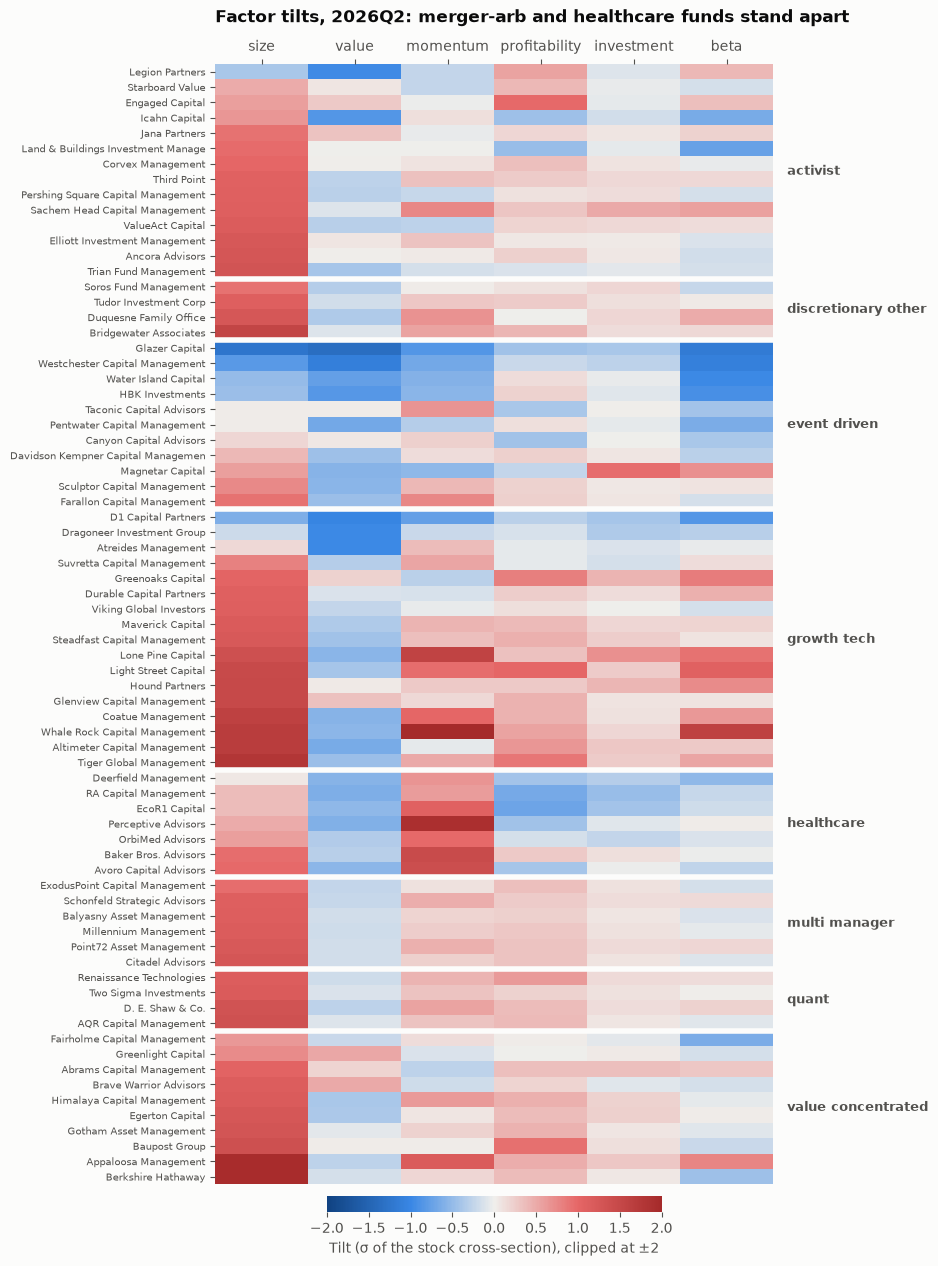

shape: (8, 7)
┌─────────────────────┬──────┬───────┬──────────┬───────────────┬────────────┬───────┐
│ style_guess         ┆ size ┆ value ┆ momentum ┆ profitability ┆ investment ┆ beta  │
│ ---                 ┆ ---  ┆ ---   ┆ ---      ┆ ---           ┆ ---        ┆ ---   │
│ str                 ┆ f64  ┆ f64   ┆ f64      ┆ f64           ┆ f64        ┆ f64   │
╞═════════════════════╪══════╪═══════╪══════════╪═══════════════╪════════════╪═══════╡
│ activist            ┆ 1.05 ┆ -0.06 ┆ -0.01    ┆ 0.21          ┆ 0.04       ┆ -0.08 │
│ discretionary_other ┆ 1.18 ┆ -0.24 ┆ 0.42     ┆ 0.18          ┆ 0.15       ┆ 0.1   │
│ event_driven        ┆ 0.03 ┆ -0.58 ┆ -0.32    ┆ 0.11          ┆ -0.0       ┆ -0.41 │
│ growth_tech         ┆ 1.21 ┆ -0.43 ┆ 0.34     ┆ 0.38          ┆ 0.18       ┆ 0.27  │
│ healthcare          ┆ 0.49 ┆ -0.53 ┆ 1.09     ┆ -0.41         ┆ -0.24      ┆ -0.18 │
│ multi_manager       ┆ 1.15 ┆ -0.17 ┆ 0.24     ┆ 0.3           ┆ 0.1        ┆ -0.08 │
│ quant               ┆ 1.25 

In [4]:
FACT = ["size", "value", "momentum", "profitability", "investment", "beta"]
tilts = (con.execute(f"""
    SELECT fund_id, fund_name, {", ".join("tilt_" + f for f in FACT)}
    FROM fund_quarter WHERE quarter = '2026Q2' AND n_positions > 0
""").pl().join(seed.select("fund_id", "style_guess"), on="fund_id", how="left")
          .sort("style_guess", "tilt_size"))
mat = np.clip(tilts.select([f"tilt_{f}" for f in FACT]).to_numpy().astype(float), -2, 2)

fig, ax = plt.subplots(figsize=(7.2, 15))
im = ax.imshow(mat, cmap=DIVERGING, vmin=-2, vmax=2, aspect="auto", interpolation="nearest")
ax.set_xticks(range(len(FACT)), FACT, rotation=0)
ax.xaxis.tick_top()
ax.set_yticks(range(len(tilts)), [n[:34] for n in tilts["fund_name"]], fontsize=7.5)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
# style group separators and labels
styles = tilts["style_guess"].to_list()
starts = [0] + [i for i in range(1, len(styles)) if styles[i] != styles[i - 1]]
for k, s in enumerate(starts):
    end = starts[k + 1] if k + 1 < len(starts) else len(styles)
    if s:
        ax.axhline(s - 0.5, color=SURFACE, linewidth=4)
    ax.text(len(FACT) - 0.35, (s + end - 1) / 2, styles[s].replace("_", " "), va="center", ha="left",
            fontsize=9, color=INK2, fontweight="bold")
cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.02, pad=0.01, shrink=0.6)
cb.set_label("Tilt (σ of the stock cross-section), clipped at ±2", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Factor tilts, 2026Q2: merger-arb and healthcare funds stand apart", pad=30)
save(fig, "03_factor_tilts_heatmap.png")
plt.show()

print(tilts.group_by("style_guess").agg([pl.col(f"tilt_{f}").median().round(2).alias(f) for f in FACT])
      .sort("style_guess"))

**Reading.** Most funds are red on size (median tilt about +1.2σ), because
value-weighting large holdings against an equal-weighted cross-section always
tilts large; the exceptions are what carry information. Event-driven funds are
the clearest block: the merger-arbitrage shops (Glazer, Westchester, Water
Island, HBK) tilt small, low book-to-market and low beta (style median beta
−0.41), consistent with holding deal targets that move on deal news rather
than with the market. Healthcare funds share high momentum (+1.09σ median) and
low profitability (−0.41σ) — biotech. Multi-managers and quants are nearly
identical rows, and some "growth/tech" funds (D1, Dragoneer) tilt small rather
than mega-cap: the weak style labels and the holdings don't always agree,
which is what the Milestone 4 classifier has to sort out.

## 4. Pershing Square's portfolio over time

100% stacked bars of long weights per quarter (both filer IDs combined, see
`fund_book_decisions`). The seven names with the highest peak weight keep
one fixed color across quarters; everything else is "Other". GOOG and GOOGL
are combined as Alphabet.

saved docs/figures/04_pershing_square_over_time.png


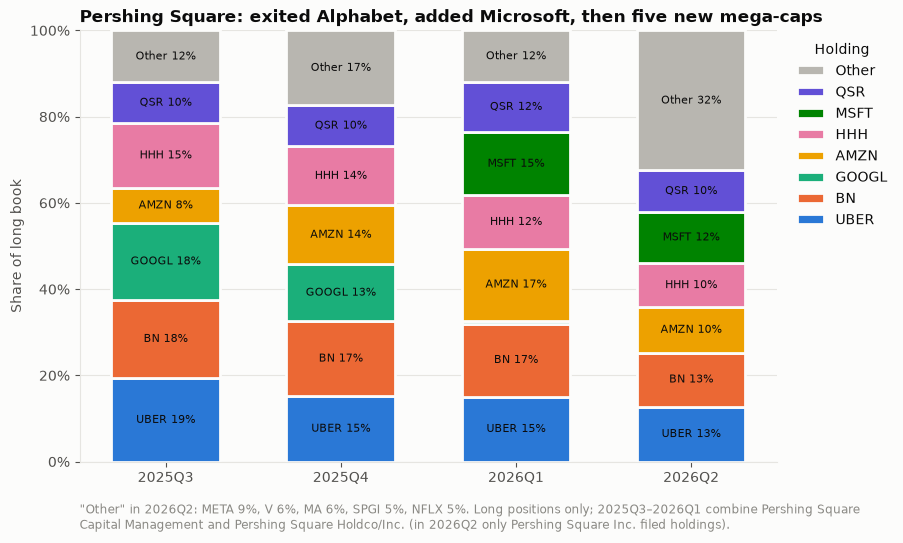

shape: (8, 5)
┌───────┬──────────┬──────────┬──────────┬──────────┐
│ name  ┆ 2025Q4   ┆ 2025Q3   ┆ 2026Q2   ┆ 2026Q1   │
│ ---   ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ str   ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞═══════╪══════════╪══════════╪══════════╪══════════╡
│ AMZN  ┆ 0.136517 ┆ 0.08312  ┆ 0.104857 ┆ 0.166982 │
│ BN    ┆ 0.173459 ┆ 0.182877 ┆ 0.125766 ┆ 0.169141 │
│ GOOGL ┆ 0.132137 ┆ 0.176677 ┆ null     ┆ 0.006912 │
│ HHH   ┆ 0.136769 ┆ 0.148777 ┆ 0.10229  ┆ 0.123352 │
│ MSFT  ┆ null     ┆ null     ┆ 0.118939 ┆ 0.146529 │
│ Other ┆ 0.17313  ┆ 0.120214 ┆ 0.324715 ┆ 0.119054 │
│ QSR   ┆ 0.096044 ┆ 0.095548 ┆ 0.096185 ┆ 0.117162 │
│ UBER  ┆ 0.151944 ┆ 0.192787 ┆ 0.127248 ┆ 0.150867 │
└───────┴──────────┴──────────┴──────────┴──────────┘


In [5]:
ps = con.execute("""
    SELECT quarter, CASE WHEN symbol IN ('GOOG', 'GOOGL') THEN 'GOOGL' ELSE coalesce(symbol, name_of_issuer) END AS name,
           sum(weight_long) AS w
    FROM positions WHERE fund_id = 'pershing_square_capital_management' AND NOT is_option
    GROUP BY ALL
""").pl()
keep = ps.group_by("name").agg(pl.col("w").max()).sort("w", descending=True).head(7)["name"].to_list()
ps = (ps.with_columns(pl.when(pl.col("name").is_in(keep)).then(pl.col("name")).otherwise(pl.lit("Other")).alias("name"))
        .group_by("quarter", "name").agg(pl.col("w").sum()))
quarters = sorted(ps["quarter"].unique())
names = keep + ["Other"]
colors = dict(zip(keep, SERIES)) | {"Other": OTHER}

fig, ax = plt.subplots(figsize=(9, 5.6))
bottom = np.zeros(len(quarters))
for name in names:
    w = np.array([ps.filter((pl.col("quarter") == q) & (pl.col("name") == name))["w"].sum() for q in quarters])
    ax.bar(range(len(quarters)), w, bottom=bottom, width=0.62, color=colors[name], edgecolor=SURFACE, linewidth=2,
           label=name)
    for i, (b, h) in enumerate(zip(bottom, w)):
        if h >= 0.04:  # direct labels: the light series hues need them (contrast < 3:1)
            ax.text(i, b + h / 2, f"{name} {h:.0%}", ha="center", va="center", fontsize=8, color=INK)
    bottom += w
ax.set_xticks(range(len(quarters)), quarters)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Share of long book")
ax.grid(axis="x", visible=False)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False,
          title="Holding")  # same top-to-bottom order as the stack
ax.set_title("Pershing Square: exited Alphabet, added Microsoft, then five new mega-caps")
raw_last = con.execute("""
    SELECT CASE WHEN symbol IN ('GOOG', 'GOOGL') THEN 'GOOGL' ELSE coalesce(symbol, name_of_issuer) END AS name,
           sum(weight_long) AS w
    FROM positions WHERE fund_id = 'pershing_square_capital_management' AND NOT is_option AND quarter = ?
    GROUP BY ALL ORDER BY w DESC
""", [quarters[-1]]).pl().filter(~pl.col("name").is_in(keep) & (pl.col("w") >= 0.03))
inside = ", ".join(f"{n} {w:.0%}" for n, w in raw_last.iter_rows())
fig.text(0.125, -0.01, f"\"Other\" in {quarters[-1]}: {inside}. Long positions only; 2025Q3–2026Q1 combine Pershing Square "
         "Capital Management and Pershing Square Holdco/Inc. (in 2026Q2 only Pershing Square Inc. filed holdings).",
         color=MUTED, fontsize=8.5, wrap=True)
save(fig, "04_pershing_square_over_time.png")
plt.show()
print(ps.pivot(on="quarter", index="name", values="w").sort("name"))

**Reading.** Pershing Square holds 11–14 long positions, and the seven named
here are 68–88% of the book in every quarter (active share 0.89 in 2026Q2).
The core stays — Uber, Brookfield, Howard Hughes and Restaurant Brands are in
every quarter at 10–19% each — while the rest rotates: Alphabet goes from 18%
to 13% to under 1% and is gone by 2026Q2, Microsoft arrives at 15% in 2026Q1,
and 2026Q2 adds Meta, Visa, Mastercard, S&P Global and Netflix, which is why
"Other" jumps to 32%. Clear exits and initiations like these are the events
the next-quarter move model (Milestone 6) is meant to predict.